<a href="https://colab.research.google.com/github/dilekmirac/dip/blob/main/hafta7_h%C3%B6rev3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import cv2
import torch

print(f"OpenCV Versiyonu: {cv2.__version__}")
print(f"CUDA Kullanılabilir mi (PyTorch/GPU): {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"Aktif GPU Modeli: {torch.cuda.get_device_name(0)}")

OpenCV Versiyonu: 4.14.0
CUDA Kullanılabilir mi (PyTorch/GPU): True
Aktif GPU Modeli: Tesla T4


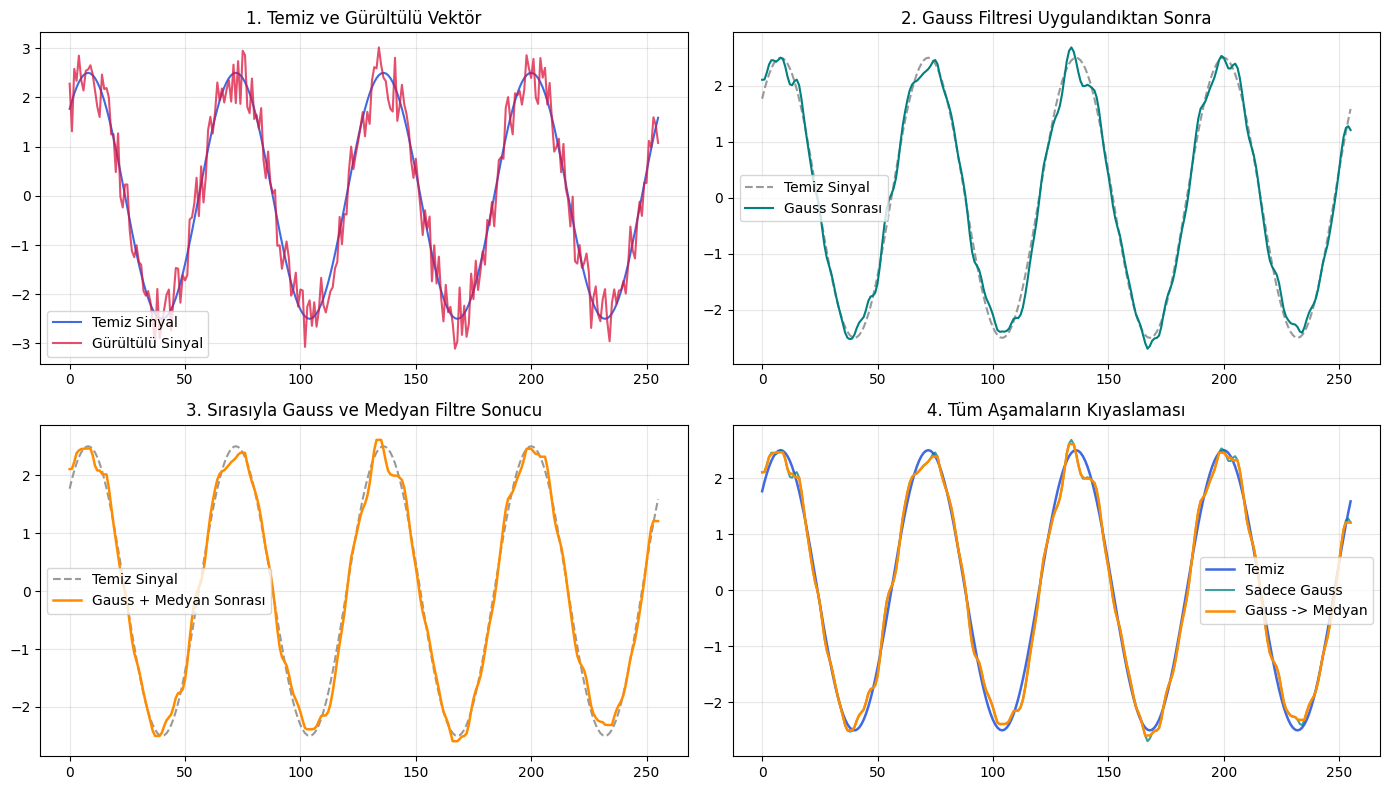

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import median_filter

def doldur_sinus(vec, amplitude=2.5, frequency=4.0, phase=np.pi/4, fs=256.0):
    n = len(vec)
    if n <= 0 or (n & (n - 1)) != 0:
        raise ValueError("Vektör boyutu 2'nin kuvveti olmalıdır.")
    t = np.arange(n, dtype=np.float64) / fs
    vec[:] = amplitude * np.sin(2.0 * np.pi * frequency * t + phase)
    return vec

def gurultu_ekle(vec, noise_ratio):
    if not (0.0 <= noise_ratio <= 1.0):
        raise ValueError("Gürültü oranı [0, 1] aralığında olmalıdır.")
    vec_arr = np.asarray(vec, dtype=np.float64)
    peak_amp = np.max(np.abs(vec_arr))
    if peak_amp == 0:
        peak_amp = 1.0
    noise = np.random.uniform(-1.0, 1.0, size=vec_arr.shape) * (noise_ratio * peak_amp)
    return vec_arr + noise

def gauss_filtre_1d(vec, kernel_size=7, sigma=1.5):
    ax = np.arange(-(kernel_size // 2), (kernel_size // 2) + 1, dtype=np.float64)
    kernel = np.exp(-0.5 * (ax / sigma) ** 2)
    kernel /= np.sum(kernel)
    pad_w = kernel_size // 2
    padded = np.pad(vec, pad_w, mode='edge')
    return np.convolve(padded, kernel, mode='valid')

N = 256
clean_vec = np.zeros(N, dtype=np.float64)
doldur_sinus(clean_vec, amplitude=2.5, frequency=4.0, phase=np.pi/4, fs=N)

noisy_vec = gurultu_ekle(clean_vec, noise_ratio=0.25)

gauss_vec = gauss_filtre_1d(noisy_vec, kernel_size=7, sigma=1.5)

gauss_then_median_vec = median_filter(gauss_vec, size=5, mode='nearest')

plt.figure(figsize=(14, 8))

plt.subplot(2, 2, 1)
plt.plot(clean_vec, label='Temiz Sinyal', color='royalblue')
plt.plot(noisy_vec, label='Gürültülü Sinyal', color='crimson', alpha=0.75)
plt.title('1. Temiz ve Gürültülü Vektör')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(2, 2, 2)
plt.plot(clean_vec, '--', label='Temiz Sinyal', color='gray', alpha=0.8)
plt.plot(gauss_vec, label='Gauss Sonrası', color='teal')
plt.title('2. Gauss Filtresi Uygulandıktan Sonra')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(2, 2, 3)
plt.plot(clean_vec, '--', label='Temiz Sinyal', color='gray', alpha=0.8)
plt.plot(gauss_then_median_vec, label='Gauss + Medyan Sonrası', color='darkorange', linewidth=1.8)
plt.title('3. Sırasıyla Gauss ve Medyan Filtre Sonucu')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(2, 2, 4)
plt.plot(clean_vec, label='Temiz', color='royalblue', linewidth=1.8)
plt.plot(gauss_vec, label='Sadece Gauss', color='teal', alpha=0.75)
plt.plot(gauss_then_median_vec, label='Gauss -> Medyan', color='darkorange', linewidth=1.8)
plt.title('4. Tüm Aşamaların Kıyaslaması')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()